In [44]:
import numpy as np
import os
import cv2
import matplotlib.pyplot as plt
import random
import time
import numpy as np
import tensorflow as tf
import imgaug.augmenters as iaa
import albumentations as A
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from keras.utils import to_categorical

c:\Users\DIVYANSH DESHMUKH\AppData\Local\Programs\Python\Python39\lib\site-packages\albumentations\__init__.py:24: UserWarning: A new version of Albumentations is available: 1.4.19 (you have 0.0.19). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


In [30]:
def assign_label(flower_type):
    if flower_type == 'daisy':
        return 1
    elif flower_type == 'dandelion':
        return 2
    elif flower_type == 'rose':
        return 3
    elif flower_type == 'sunflower':
        return 4
    elif flower_type == 'tulip':   
        return 0


In [31]:


classes = ['tulip', 'daisy', 'dandelion', 'rose', 'sunflower']

X = []
Z = []


inputdataset = r"C:\Users\DIVYANSH DESHMUKH\Desktop\Semester\Seventh Semester\Deep Learning\DL\flowers"

for flower in os.listdir(inputdataset):
    flower_path = os.path.join(inputdataset, flower)  

    if not os.path.isdir(flower_path):  
        continue

    for filename in os.listdir(flower_path):
        img_path = os.path.join(flower_path, filename)  
        img = cv2.imread(img_path, cv2.IMREAD_COLOR)

        if img is None:
            print(f"Warning: {img_path} could not be loaded.")
            continue
        img = cv2.resize(img, (224, 224))
        label = assign_label(flower)
        X.append(np.array(img / 255))
        Z.append(label)




In [35]:
X = np.array(X)
Z = np.array(Z)
Y = to_categorical(Z, 5)


print(f"Shape of X: {X.shape}")
print(f"Shape of Y: {Y.shape}")
print(f"Shape of Z: {Z.shape}")

Shape of X: (4317, 224, 224, 3)
Shape of Y: (4317, 5)
Shape of Z: (4317,)


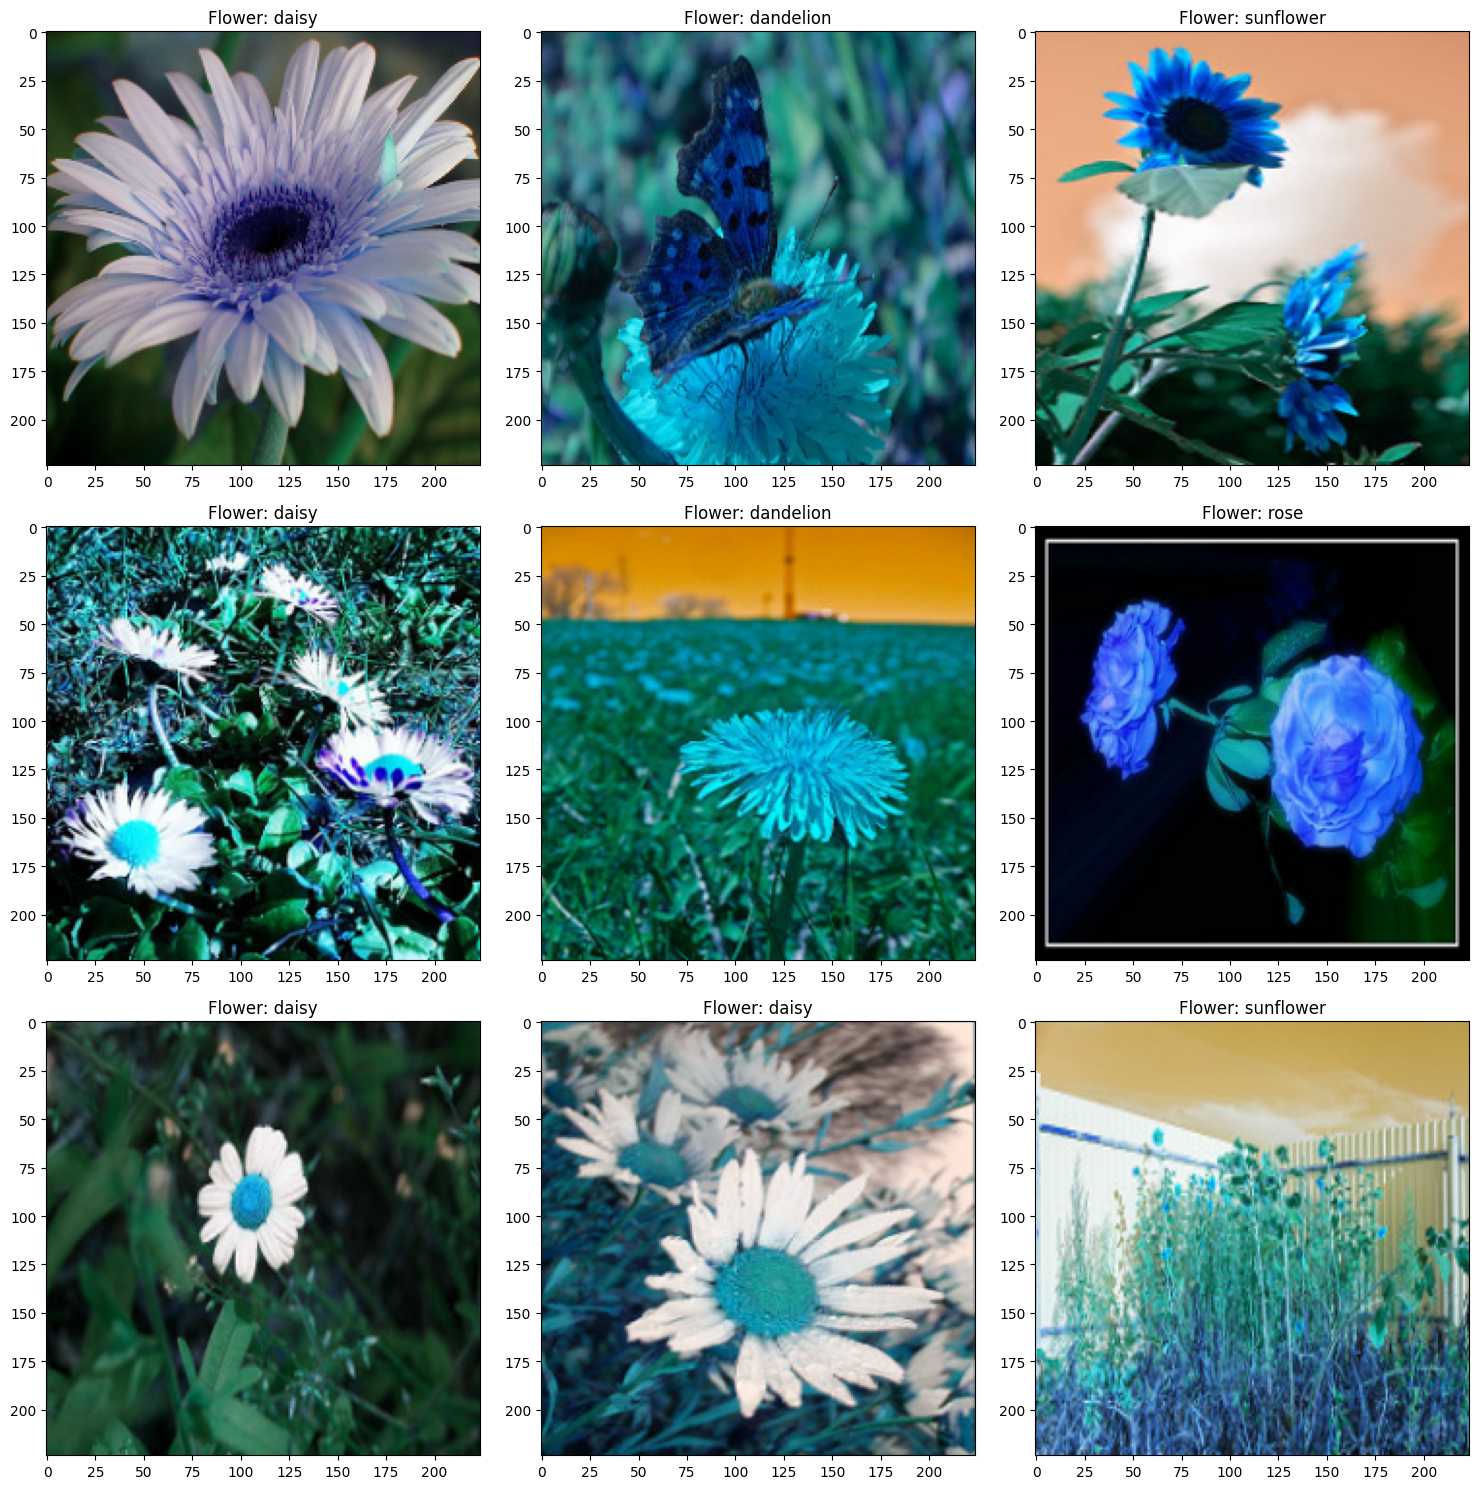

In [32]:
figure, axes = plt.subplots(3, 3)
figure.set_size_inches(15, 15)

for row in range(3):
    for col in range(3):
        index = random.randint(0, len(X) - 1)

        image = X[index]
        flower_label = Z[index]

        axes[row, col].imshow(image)
        axes[row, col].set_title(f"Flower: {classes[flower_label]}")

plt.tight_layout()
plt.show()

In [36]:
indices = np.arange(len(X))
np.random.shuffle(indices)

train_indices = indices[:500]
test_indices = indices[500:750]

X_train = X[train_indices]
Y_train = Y[train_indices]
X_test = X[test_indices]
Y_test = Y[test_indices]

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of Y_train: {Y_train.shape}")
print(f"Shape of Y_test: {Y_test.shape}")

Shape of X_train: (500, 224, 224, 3)
Shape of X_test: (250, 224, 224, 3)
Shape of Y_train: (500, 5)
Shape of Y_test: (250, 5)


In [ ]:
# Define the model
model = Sequential()

# Add convolutional layers
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Flatten the layers
model.add(Flatten())

# Add fully connected layers
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(5, activation='softmax'))

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(X_train, Y_train, epochs=10, batch_size=32, validation_data=(X_test, Y_test))

In [21]:
# Define the model
model = Sequential()

# Add convolutional layers
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Flatten the layers
model.add(Flatten())

# Add fully connected layers
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(5, activation='softmax'))

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model with time estimation
epochs = 10
batch_size = 32
start_time = time.time()

for epoch in range(epochs):
    epoch_start_time = time.time()
    model.fit(X_train, Y_train, epochs=1, batch_size=batch_size, validation_data=(X_test, Y_test))
    epoch_end_time = time.time()
    
    elapsed_time = epoch_end_time - start_time
    avg_epoch_time = elapsed_time / (epoch + 1)
    remaining_time = avg_epoch_time * (epochs - epoch - 1)
    
    print(f"Epoch {epoch + 1}/{epochs} completed in {epoch_end_time - epoch_start_time:.2f} seconds.")
    print(f"Estimated remaining time: {remaining_time:.2f} seconds.")

total_time = time.time() - start_time
print(f"Total training time: {total_time:.2f} seconds.")

c:\Users\DIVYANSH DESHMUKH\AppData\Local\Programs\Python\Python39\lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


16/16 ━━━━━━━━━━━━━━━━━━━━ 15s 782ms/step - accuracy: 0.2167 - loss: 2.3731 - val_accuracy: 0.3440 - val_loss: 1.4975
Epoch 1/10 completed in 17.74 seconds.
Estimated remaining time: 159.69 seconds.
16/16 ━━━━━━━━━━━━━━━━━━━━ 11s 662ms/step - accuracy: 0.3164 - loss: 1.4968 - val_accuracy: 0.4840 - val_loss: 1.2985
Epoch 2/10 completed in 13.25 seconds.
Estimated remaining time: 123.98 seconds.
16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 656ms/step - accuracy: 0.4210 - loss: 1.3565 - val_accuracy: 0.4280 - val_loss: 1.1990
Epoch 3/10 completed in 10.91 seconds.
Estimated remaining time: 97.79 seconds.
16/16 ━━━━━━━━━━━━━━━━━━━━ 10s 650ms/step - accuracy: 0.4609 - loss: 1.2681 - val_accuracy: 0.5240 - val_loss: 1.1048
Epoch 4/10 completed in 10.82 seconds.
Estimated remaining time: 79.09 seconds.
16/16 ━━━━━━━━━━━━━━━━━━━━ 11s 671ms/step - accuracy: 0.5186 - loss: 1.1997 - val_accuracy: 0.5520 - val_loss: 1.0953
Epoch 5/10 completed in 11.10 seconds.
Estimated remaining time: 63.83 seconds.
16/16 ━━

In [59]:
def random_rotate(image, magnitude):
    """Rotate the image by a random angle between -magnitude and magnitude."""
    angle = np.random.uniform(-magnitude, magnitude)
    return tf.image.rot90(image, k=int(angle))

def random_translate(image, magnitude):
    """Translate the image by a random distance in x and y direction."""
    translate_x = np.random.uniform(-magnitude, magnitude) * image.shape[1]
    translate_y = np.random.uniform(-magnitude, magnitude) * image.shape[0]
    return tf.keras.preprocessing.image.apply_affine_transform(
        image, tx=translate_x, ty=translate_y
    )

def random_shear(image, magnitude):
    """Shear the image by a random magnitude."""
    shear_val = np.random.uniform(-magnitude, magnitude)
    return tf.keras.preprocessing.image.apply_affine_transform(
        image, shear=shear_val
    )

def random_brightness(image, magnitude):
    """Adjust brightness randomly."""
    brightness = np.random.uniform(-magnitude, magnitude)
    return tf.image.adjust_brightness(image, brightness)

def random_contrast(image, magnitude):
    """Adjust contrast randomly."""
    contrast = np.random.uniform(1 - magnitude, 1 + magnitude)
    return tf.image.adjust_contrast(image, contrast)

def random_flip(image, _):
    """Randomly flip the image horizontally."""
    return tf.image.random_flip_left_right(image)

# Combine these functions into a list of augmentations
augmentations = [random_rotate, random_translate, random_shear, 
                 random_brightness, random_contrast, random_flip]

# RandAugment function
def rand_augment(image, n_ops=3, magnitude=0.2):
    """Apply RandAugment: choose n_ops random augmentations and apply them."""
    for _ in range(n_ops):
        op = random.choice(augmentations)  # Randomly choose an operation
        image = op(image, magnitude)       # Apply the operation with magnitude
    return image

# Example usage
image = tf.random.uniform(shape=(224, 224, 3))  # Random example image

# Apply RandAugment
augmented_image = rand_augment(image, n_ops=2, magnitude=0.3)

# Convert back to numpy to visualize if needed
augmented_image_numpy = augmented_image.numpy()


In [60]:
random_indices = np.random.choice(len(X_train), 100, replace=False)

augmented_images = [rand_augment(X_train[i]) for i in random_indices]
augmented_images = np.array(augmented_images)

X_train = np.concatenate((X_train, augmented_images), axis=0)

print(f"New shape of X_train: {X_train.shape}")

C:\Users\DIVYANSH DESHMUKH\AppData\Local\Temp\ipykernel_6092\432187599.py:4: DeprecationWarning: Flip is deprecated. Consider using HorizontalFlip, VerticalFlip, RandomRotate90 or D4.
  A.Flip(),


error: OpenCV(4.9.0) D:\a\opencv-python\opencv-python\opencv\modules\core\src\arithm.cpp:674: error: (-5:Bad argument) When the input arrays in add/subtract/multiply/divide functions have different types, the output array type must be explicitly specified in function 'cv::arithm_op'
